# Notebook 04: LoRA adaptation for the B versus C comparison

This notebook explains the adaptation method planned for condition C, why it was chosen, and what has actually been run. So far that is a four-step CPU smoke test. Its purpose was to check that the pipeline works, not to train a useful adapter, and nothing in this notebook is a quality result.

The comparison it serves is B versus C. Both use the same pinned base model (`Qwen/Qwen2.5-1.5B-Instruct`, revision `989aa79…`), the same tokenizer, the same system prompt (B-dev-revision-2) and the same greedy decoding. C differs only in having an adapter. If the prompt changed as well, any difference could not be attributed to the weights.


## 1. The mathematics of LoRA

A linear layer in the attention block computes $h = W x$, where $W \in \mathbb{R}^{d_{out} \times d_{in}}$. Full fine-tuning learns an update $\Delta W$ of the same size. LoRA (Hu et al., 2021) restricts that update to low rank:

$$h = W x + \frac{\alpha}{r} B A x, \qquad A \in \mathbb{R}^{r \times d_{in}},\; B \in \mathbb{R}^{d_{out} \times r},\; r \ll \min(d_{in}, d_{out}).$$

$W$ stays frozen. $A$ starts with small random values and $B$ starts at zero, so $BA = 0$ at the first step and the adapted model begins exactly where the base model is. The scale $\alpha / r$ (here $16/8 = 2$) means that changing $r$ does not force the learning rate to be re-tuned from scratch.

Each adapted matrix adds $r(d_{in} + d_{out})$ parameters. In Qwen2.5-1.5B the hidden size is 1536. `q_proj` maps 1536 to 1536. `v_proj` maps 1536 to 256, because grouped-query attention uses 2 key/value heads of size 128. With $r = 8$:

- `q_proj`: $8 \times (1536 + 1536) = 24{,}576$
- `v_proj`: $8 \times (1536 + 256) = 14{,}336$
- per layer: $38{,}912$; over 28 layers: $1{,}089{,}536$

The next cell checks that figure against the tensors in the saved adapter, rather than trusting the arithmetic.


In [1]:
import json
from pathlib import Path
from safetensors import safe_open

adapter = Path('adapters/smoke-v1')
cfg = json.loads((adapter / 'adapter_config.json').read_text())
print({k: cfg[k] for k in ('r', 'lora_alpha', 'lora_dropout', 'target_modules')})
shapes = {}
with safe_open(str(adapter / 'adapter_model.safetensors'), framework='pt') as f:
    for k in f.keys():
        shapes[k] = tuple(f.get_slice(k).get_shape())
total = sum(a * b for a, b in shapes.values())
example = {k: v for k, v in shapes.items() if '.layers.0.' in k}
for k, v in sorted(example.items()):
    print(k.split('layers.0.')[1], v)
print('tensors:', len(shapes), ' parameters:', total)
assert total == 1_089_536


{'r': 8, 'lora_alpha': 16, 'lora_dropout': 0.05, 'target_modules': ['q_proj', 'v_proj']}
self_attn.q_proj.lora_A.weight (8, 1536)
self_attn.q_proj.lora_B.weight (1536, 8)
self_attn.v_proj.lora_A.weight (8, 1536)
self_attn.v_proj.lora_B.weight (256, 8)
tensors: 112  parameters: 1089536


## 2. Why LoRA, and the alternatives considered

| Option | Why it was not the first choice |
|---|---|
| Full fine-tuning | 1.54 billion trainable parameters need optimiser state several times the model size. It does not fit the available hardware and risks overwriting general ability with a few hundred examples. |
| QLoRA (Dettmers et al., 2023) | Saves memory by quantising the frozen base to 4 bits, but C would then run on a differently quantised base from B. That would be a second treatment. It also needs CUDA-only kernels, so it is deferred. |
| Prompt-only (more prompt revisions) | This is condition B. The question is whether weights add anything beyond it. |
| Prefix or prompt tuning | Fewer parameters, but less evidence for small chat models, and the learned prefix interacts with the system prompt that B and C are supposed to share. |
| Larger rank or more target modules | Pre-registered as a later ablation. Starting small keeps the adapter close to the base model and makes overfitting easier to see. |

`q_proj` and `v_proj` are the targets used in the original LoRA paper's main experiments. They are a conventional starting point, not a choice that was tuned here.


## 3. Data selection

Training rows come from the official EmpatheticDialogues train partition (CC BY-NC 4.0). Validation rows come from the separate validation partition. `scripts/lora_pilot.py` checks the training file's SHA-256 before it starts and selects **whole conversation groups** with seed 42, so that turns from one conversation never appear on both sides of a split. The final 60-case test set is not an input to the script at all, and the manifest records `final_test_read: false`.

Every example is built with the model's chat template: prompt B as the system message, the dialogue context as earlier turns and the reference response as the assistant turn. The labels are masked so that loss is computed **only on assistant tokens**. The script checks that the tokenised prompt is an exact prefix of the tokenised full conversation, so masking cannot drift by a token. Examples whose assistant tokens are entirely cut off by truncation are dropped and counted.


In [2]:
m = json.loads(Path('results/lora/smoke-v1/manifest.json').read_text())
sel = json.loads(Path('results/lora/smoke-v1/selection.json').read_text())
for k in ('train_sha256', 'train_rows', 'train_groups', 'train_examples', 'train_truncated', 'train_dropped_fully_truncated',
          'val_rows', 'val_groups', 'val_examples', 'val_dropped_fully_truncated', 'train_target_tokens', 'final_test_read'):
    print(f'{k:32} {m[k]}')
print('first selected ids:', sel['train_ids'][:3])


train_sha256                     fea592b7ad462e191cd5fe56b3b5b21751be4bcb7f2dd92798114b2a51101fd6
train_rows                       16
train_groups                     9
train_examples                   15
train_truncated                  3
train_dropped_fully_truncated    1
val_rows                         8
val_groups                       4
val_examples                     7
val_dropped_fully_truncated      1
train_target_tokens              172
final_test_read                  False
first selected ids: ['hit:3896_conv:7792_t4', 'hit:3896_conv:7792_t2', 'hit:5744_conv:11488_t4']


## 4. Hyperparameters

These were fixed in `configs/milestone_4.pilot.json` before any training. They are starting hypotheses, not tuned values.

| Setting | Value | Reason |
|---|---|---|
| rank `r` / alpha | 8 / 16 | Small update; scale 2 |
| dropout | 0.05 | Light regularisation for a few hundred rows |
| learning rate | 1e-4 or 2e-4 | The only setting to be compared; chosen on validation loss plus a development safety review |
| max length | 512 tokens (256 in the smoke test) | Covers most EmpatheticDialogues contexts |
| gradient accumulation | 8 (2 in the smoke test) | Effective batch of 8 with batch size 1 |
| seed | 42 | Same as generation |

The smoke test shortened every setting so that it would finish on a CPU in a few minutes.


## 5. What the smoke test showed

Four optimiser steps (eight micro-batches) on CPU in float32. The plot shows each micro-batch loss, which is noisy because each one is a single example, together with the mean validation loss before and after training.


training seconds: 176.5  RSS after training (GB): 7.25  adapter MB: 4.38  device: cpu 2.8.0+cpu


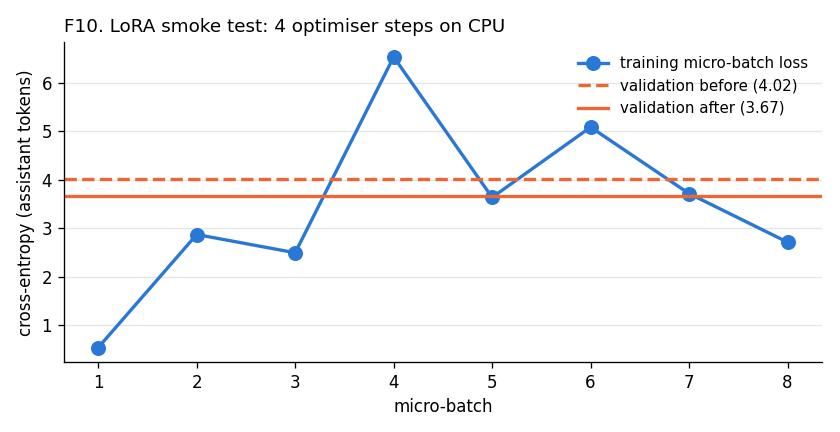

In [3]:
import matplotlib.pyplot as plt
rows = [json.loads(s) for s in Path('results/lora/smoke-v1/losses.jsonl').read_text().splitlines() if s.strip()]
micro = [r for r in rows if 'micro_step' in r]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot([r['micro_step'] for r in micro], [r['loss'] for r in micro], color='#2a78d6', lw=2, marker='o', ms=8, label='training micro-batch loss')
ax.axhline(m['val_loss_before'], color='#eb6834', lw=2, ls='--', label=f"validation before ({m['val_loss_before']:.2f})")
ax.axhline(m['val_loss_after'], color='#eb6834', lw=2, label=f"validation after ({m['val_loss_after']:.2f})")
ax.set_xlabel('micro-batch'); ax.set_ylabel('cross-entropy (assistant tokens)')
ax.set_title('F10. LoRA smoke test: 4 optimiser steps on CPU', loc='left', fontsize=11)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.grid(axis='y', color='#e5e5e5'); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
print('training seconds:', round(m['training_seconds'], 1), ' RSS after training (GB):', round(m['rss_after_training_bytes'] / 1e9, 2),
      ' adapter MB:', round(m['adapter_bytes'] / 1e6, 2), ' device:', m['device'], m['torch'])


The validation loss fell from 4.02 to 3.67. That is consistent with the update going in a sensible direction, but it is **not evidence of learning**. It comes from four steps, 15 training examples and only 7 validation examples, and a drop at this scale can come from the model simply picking up the response format. What the run does establish:

- the masked loss is finite and the gradients reach only the adapter (1,089,536 trainable parameters out of 1.54 billion);
- the adapter saves, reloads in `scripts/generate_bc.py`, and can be switched off to give condition B from the same loaded model;
- the manifest records the data hashes, versions, timings, memory and `final_test_read: false`.

**Cost.** About 44 s per optimiser step with an effective batch of 2 at 256 tokens on 16 CPU threads. A 256-row pilot at 512 tokens would take several hours on this CPU. The laptop's RTX 4060 is not usable because the installed PyTorch is a CPU build. Installing a CUDA build of PyTorch, or using a hosted GPU, is a prerequisite for the pilot, and so is the author's approval.


## 6. Failures and risks to watch in the pilot

- **Overfitting to stock warmth.** EmpatheticDialogues responses are short and often formulaic. An adapter could make C sound more generic, not more supportive. The lexical stock-phrase rate from notebook 07 should be tracked, but only blinded ratings can settle it.
- **Safety drift.** Training on casual dialogue could weaken prompt B's instructions on risk. The development safety review (`scripts/generate_bc.py --inputs safety_v3`) runs for B and C before any learning rate is chosen.
- **Length shift.** If C writes longer replies, it will look slower and hit the token cap more often. Length has to be reported next to every latency number, as notebook 07 showed.
- **Licence.** The adapter is derived from CC BY-NC 4.0 data. It stays in the gitignored `adapters/` folder and is not published.

## 7. How C will be evaluated

On the unchanged 60-case final set, with blinded independent ratings and a separate hazard judgement, reporting paired B − C differences with intervals and per-category results. Routing (S2) is unaffected by the adapter and is reported separately. An apparent quality gain cannot offset an unexamined safety loss.

## 8. Limits of this notebook

It documents a pipeline and one smoke run. It does not show that LoRA helps, that the chosen settings are good, or that the Python CPU path matches browser inference. The pilot has not been run.
